# 01 — Data Preparation (EDA + Preprocessing + Feature Engineering)

**Purpose:** inspect the original Zhejiang weekly dataset before any modeling, identify data-quality concerns, plot demand and supply, then build the cleaned weekly records, 4 blood-type rows per date, historical lag/rolling features and next-week targets.


In [1]:
# CMD: Run this cell first. Makes imports work whether Jupyter starts from the project root or notebooks/.
from pathlib import Path
import sys
ROOT = Path.cwd()
if not (ROOT / 'src').is_dir():
    ROOT = ROOT.parent
if not (ROOT / 'src').is_dir():
    raise RuntimeError('Open Jupyter from the Blood-Type-ML project directory.')
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
import warnings
warnings.filterwarnings('ignore', category=FutureWarning)
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
pd.set_option('display.width', 160)
pd.set_option('display.max_columns', 40)
print('Project root:', ROOT)

Project root: d:\Blood-Type-ML


## Part A — Exploratory data analysis
### Step 1: Inspect the raw dataset
Check file dimensions, variable names, first rows, dates and duplicate entries.

In [2]:
# CMD: Load the unmodified original CSV and summarize its contents.
from src.config import RAW_DATA, BLOOD_TYPES, HIGH_RISK_COVERAGE, LOW_RISK_COVERAGE
raw = pd.read_csv(RAW_DATA)
print('Raw shape:', raw.shape)
display(raw.head())
print('Columns:', list(raw.columns))
print('Exact duplicate rows:', raw.duplicated().sum())

Raw shape: (639, 69)


,date,collected_total,collected_A,collected_B,collected_O,collected_AB,team_total,Individual_donate,demand_total,demand_A,demand_B,demand_O,demand_AB,supply_total,supply_A,supply_B,supply_O,supply_AB,platelet_collection,platelet_collection_tx_units,...,next_week_new_year_days,next_week_spring_festival_days,next_week_qingming_days,next_week_labour_day_days,next_week_dragon_boat_days,next_week_mid_autumn_days,next_week_national_day_days,next_week_other_holiday_days,gdp_quarter_100m_yuan,gdp_primary_100m_yuan,gdp_secondary_100m_yuan,gdp_tertiary_100m_yuan,health_institutions,medical_staff,health_staff_per_1000,health_visits,outpatient_er,population,population_male,population_female
0,3/19/2012,3896.0,1224.0,996,1389,287,1100,2796,4600,1400,1400.0,1400,400.0,3512.0,1079,948,1198,287,314.0,419.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,3/26/2012,3058.0,965.0,749,1081,263,1115,1943,4300,1400,1300.0,1300,300.0,3497.0,1081,889,1250,277,213.0,279.0,...,0.0,0.0,3.0,0.0,0.0,0.0,0.0,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,4/2/2012,3055.0,923.0,851,1007,274,399.5,2655.5,4600,1500,1500.0,1200,400.0,2818.0,813,772,935,298,328.0,455.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,4/9/2012,2887.0,908.0,782,991,206,505,2382,4700,1500,1500.0,1400,300.0,3369.0,1030,831,1234,274,305.0,398.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,4/16/2012,2915.0,800.0,819,1046,250,543.5,2371.5,4700,1500,1300.0,1500,400.0,3173.0,971.5,860,1128,213.5,283.0,350.0,...,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


Columns: ['date', 'collected_total', 'collected_A', 'collected_B', 'collected_O', 'collected_AB', 'team_total', 'Individual_donate', 'demand_total', 'demand_A', 'demand_B', 'demand_O', 'demand_AB', 'supply_total', 'supply_A', 'supply_B', 'supply_O', 'supply_AB', 'platelet_collection', 'platelet_collection_tx_units', 'platelet_collection_A', 'platelet_collection_B', 'platelet_collection_O', 'platelet_collection_AB', 'platelet_supply', 'platelet_supply_A', 'platelet_supply_B', 'platelet_supply_O', 'platelet_supply_AB', 'holiday_days_off', 'makeup_workdays', 'total_days_off', 'school_break_days_approx', 'new_year_days', 'spring_festival_days', 'qingming_days', 'labour_day_days', 'dragon_boat_days', 'mid_autumn_days', 'national_day_days', 'other_holiday_days', 'days_to_next_holiday', 'days_since_last_holiday', 'covid_stringency_mean', 'covid_stringency_max', 'next_week_holiday_days_off', 'next_week_makeup_workdays', 'next_week_total_days_off', 'next_week_school_break_days_approx', 'next_we

In [3]:
# CMD: Describe the actual date span and conflicting duplicate dates.
raw_date = pd.to_datetime(raw['date'], format='%m/%d/%Y', errors='coerce')
print('Date span:', raw_date.min().date(), 'to', raw_date.max().date())
print('Repeated date rows:', raw_date.duplicated().sum())
print('Text columns needing numeric cleanup:')
print([c for c in raw.columns if c != 'date' and not pd.api.types.is_numeric_dtype(raw[c])])

Date span: 2012-03-19 to 2024-06-17
Repeated date rows: 0
Text columns needing numeric cleanup:
['collected_B', 'collected_O', 'collected_AB', 'team_total', 'Individual_donate', 'supply_A', 'supply_B', 'supply_O', 'supply_AB']


### Step 2: Automated validation report

In [4]:
# CMD: Validate required columns, data types, dates and value ranges.
from src.data_pipeline import read_raw_csv, validate_raw
report = validate_raw(read_raw_csv(RAW_DATA))
display(report.as_frame())
print(report.summary())

,Check,Result
0,Rows,639
1,Unique dates,639
2,Date range,2012-03-19 to 2024-06-17
3,Unparsed dates (dropped),0
4,Exact duplicate rows (dropped),0
5,Repeated dates (averaged),0
6,Irregular gaps (no label created),1
7,Non-numeric cells set to missing,2
8,Negative values set to missing,0
9,Optional columns absent,0


Rows: 639 | unique dates: 639 | range: 2012-03-19 to 2024-06-17


### Step 2b: Data-entry errors and the corrected copy 

In [5]:
# CMD: Build the corrected copy and show what changed
import tempfile
from src.data_repair import repair
from src.data_pipeline import read_raw_csv, validate_raw
with tempfile.TemporaryDirectory() as tmp:
    corrected_path = Path(tmp) / 'corrected.csv'
    repair_log = repair(RAW_DATA, corrected_path, Path(tmp) / 'log.csv')
    after = validate_raw(read_raw_csv(corrected_path))
before = validate_raw(read_raw_csv(RAW_DATA))
display(pd.DataFrame({'original': [before.unique_dates, before.duplicate_dates, before.irregular_gaps],
                      'corrected': [after.unique_dates, after.duplicate_dates, after.irregular_gaps]},
                     index=['unique weeks', 'repeated dates', 'irregular gaps']))
print('Changes by column:'); display(repair_log.groupby('column').size().rename('changes').to_frame())
display(repair_log[repair_log.column != 'date'][['row', 'column', 'original', 'corrected', 'rule']])

,original,corrected
unique weeks,639,639
repeated dates,0,0
irregular gaps,1,1


Changes by column:


,changes
column,


,row,column,original,corrected,rule


### Step 3: Clean for analysis

In [6]:
# CMD: Inspect cleaned dates and missing-value counts.
from src.data_pipeline import load_and_clean
weekly = load_and_clean()
print('Unique week/date records:', len(weekly))
print(weekly.isna().sum()[weekly.isna().sum() > 0].to_string())
display(weekly[['date', 'demand_total', 'supply_total', 'collected_total']].head())

Unique week/date records: 639
collected_AB                      4
team_total                       28
Individual_donate                 4
demand_B                          1
demand_AB                         6
supply_A                          2
supply_AB                         2
platelet_collection               1
platelet_collection_tx_units      1
platelet_collection_A             1
platelet_collection_B             1
platelet_collection_O             1
platelet_collection_AB            1
gdp_quarter_100m_yuan           118
gdp_primary_100m_yuan           118
gdp_secondary_100m_yuan         118
gdp_tertiary_100m_yuan          118
health_institutions             118
medical_staff                   118
health_staff_per_1000           118
health_visits                   118
outpatient_er                   118
population                      118
population_male                 118
population_female               118


,date,demand_total,supply_total,collected_total
0,2012-03-19,4600.0,3512.0,3896.0
1,2012-03-26,4300.0,3497.0,3058.0
2,2012-04-02,4600.0,2818.0,3055.0
3,2012-04-09,4700.0,3369.0,2887.0
4,2012-04-16,4700.0,3173.0,2915.0


### Step 4: Visualize historical patterns

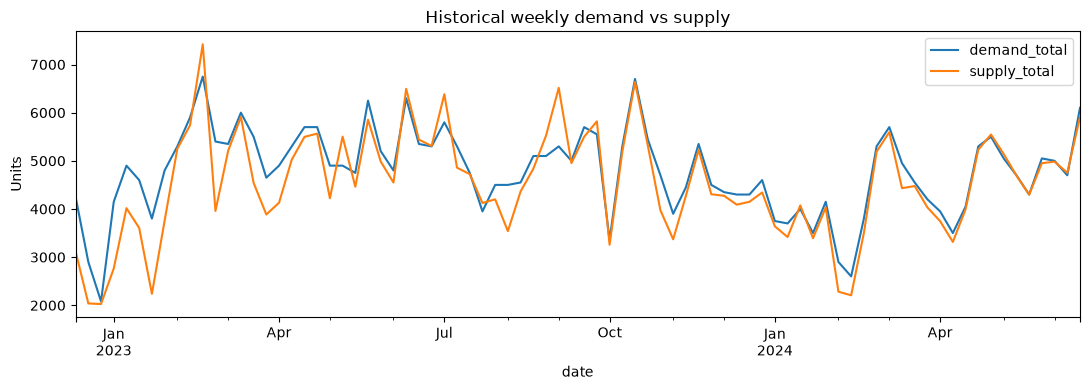

In [7]:
# CMD: Chart total demand and supply over the final 80 recorded weeks.
ax = weekly.tail(80).plot(x='date', y=['demand_total', 'supply_total'], figsize=(11, 4), title='Historical weekly demand vs supply')
ax.set_ylabel('Units')
plt.tight_layout(); plt.show()

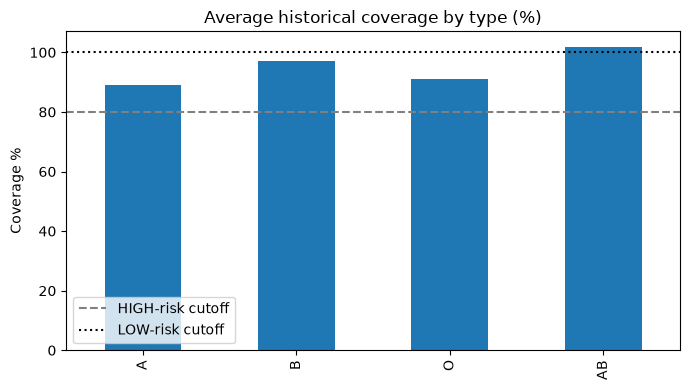

In [8]:
# CMD: Compare average supply-demand coverage by blood type.
from src.data_pipeline import safe_ratio
coverage = {bt: safe_ratio(weekly[f'supply_{bt}'], weekly[f'demand_{bt}']).mean() * 100 for bt in BLOOD_TYPES}
ax = pd.Series(coverage).plot(kind='bar', figsize=(7, 4), title='Average historical coverage by type (%)')
ax.axhline(HIGH_RISK_COVERAGE * 100, linestyle='--', color='grey', label='HIGH-risk cutoff')
ax.axhline(LOW_RISK_COVERAGE * 100, linestyle=':', color='black', label='LOW-risk cutoff')
ax.set_ylabel('Coverage %'); ax.legend()
plt.tight_layout(); plt.show()

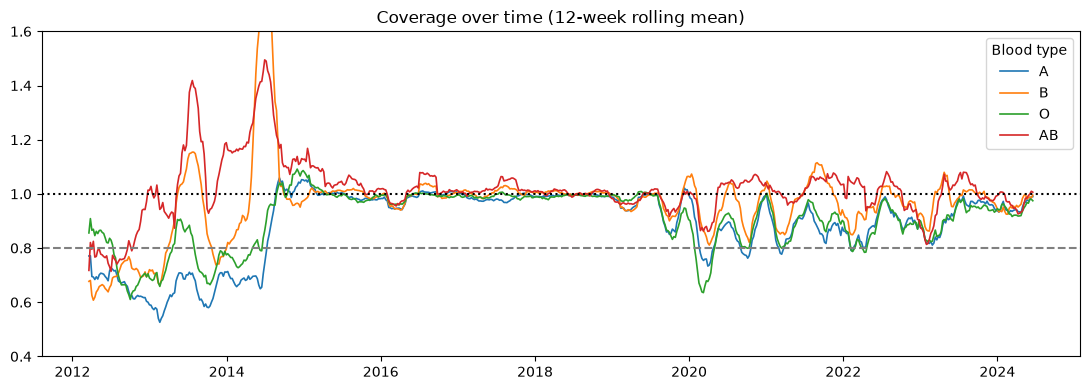

In [9]:
# CMD: Coverage over time by blood type (12-week average) with the risk cutoffs.
fig, ax = plt.subplots(figsize=(11, 4))
for bt in BLOOD_TYPES:
    cov = safe_ratio(weekly[f'supply_{bt}'], weekly[f'demand_{bt}']).rolling(12, min_periods=1).mean()
    ax.plot(weekly.date, cov, label=bt, lw=1.2)
ax.axhline(HIGH_RISK_COVERAGE, ls='--', color='grey'); ax.axhline(LOW_RISK_COVERAGE, ls=':', color='black')
ax.set_title('Coverage over time (12-week rolling mean)'); ax.legend(title='Blood type'); ax.set_ylim(0.4, 1.6)
plt.tight_layout(); plt.show()

## Part B — Preprocessing and feature engineering
### Step 5: Generate the cleaned and processed files
Writes `data/cleaned_weekly.csv` and `data/processed_data.csv`

In [10]:
# CMD: Generate cleaned_weekly.csv and processed_data.csv.
from src.data_pipeline import (generate_processed, FEATURE_SETS, ORIGINAL_NUMERICAL_FEATURES,
                               EXTENDED_NUMERICAL_FEATURES, ALL_NUMERICAL_FEATURES, check_no_leakage)
processed = generate_processed()
print('Clean dates:', processed.date.nunique(), '| feature rows:', processed.shape[0])
print('Original numeric features:', len(ORIGINAL_NUMERICAL_FEATURES), '| extended candidates:', len(EXTENDED_NUMERICAL_FEATURES))
print('Next-week labeled examples:', processed.next_risk.notna().sum())
display(processed[['date', 'blood_type', 'demand', 'supply', 'coverage', 'observed_risk', 'target_date', 'next_demand', 'next_risk']].head(10))

Clean dates: 639 | feature rows: 2556
Original numeric features: 34 | extended candidates: 13
Next-week labeled examples: 2537


,date,blood_type,demand,supply,coverage,observed_risk,target_date,next_demand,next_risk
0,2012-03-19,A,1400.0,1079.0,0.770714,High,2012-03-26,1400.0,High
1,2012-03-19,AB,400.0,287.0,0.717500,High,2012-03-26,300.0,Medium
2,2012-03-19,B,1400.0,948.0,0.677143,High,2012-03-26,1300.0,High
3,2012-03-19,O,1400.0,1198.0,0.855714,Medium,2012-03-26,1300.0,Medium
4,2012-03-26,A,1400.0,1081.0,0.772143,High,2012-04-02,1500.0,High
5,2012-03-26,AB,300.0,277.0,0.923333,Medium,2012-04-02,400.0,High
6,2012-03-26,B,1300.0,889.0,0.683846,High,2012-04-02,1500.0,High
7,2012-03-26,O,1300.0,1250.0,0.961538,Medium,2012-04-02,1200.0,High
8,2012-04-02,A,1500.0,813.0,0.542000,High,2012-04-09,1500.0,High
9,2012-04-02,AB,400.0,298.0,0.745000,High,2012-04-09,300.0,Medium


In [11]:
# CMD: Verify the risk class distribution (class imbalance) and the model input variables.
print('Class counts:\n', processed.next_risk.value_counts(dropna=False))
print('\nClass share by target year (temporal drift):')
display(pd.crosstab(processed.target_date.dt.year, processed.next_risk, normalize='index').round(2))
print('Original features (used by the original project):', ', '.join(ORIGINAL_NUMERICAL_FEATURES))
print('\nNew candidate features (kept only if time-series CV supports them):', ', '.join(EXTENDED_NUMERICAL_FEATURES))
check_no_leakage(processed, ALL_NUMERICAL_FEATURES)
assert processed.groupby('date')['blood_type'].nunique().eq(4).all()

Class counts:
 next_risk
Medium    1188
Low        927
High       422
NaN         19
Name: count, dtype: int64

Class share by target year (temporal drift):


next_risk,High,Low,Medium
target_date,,,
2012.0,0.71,0.05,0.24
2013.0,0.52,0.24,0.24
2014.0,0.19,0.54,0.27
2015.0,0.00,0.51,0.49
2016.0,0.02,0.46,0.52
2017.0,0.00,0.46,0.54
2018.0,0.00,0.45,0.55
2019.0,0.09,0.38,0.53
2020.0,0.25,0.35,0.40


Original features (used by the original project): collected, supply, demand, platelet_collection, platelet_supply, coverage, collection_efficiency, collected_total, demand_total, supply_total, team_total, Individual_donate, month, quarter, week_sin, week_cos, demand_growth, supply_growth, demand_lag1, demand_lag2, demand_lag4, supply_lag1, supply_lag2, supply_lag4, collected_lag1, collected_lag2, collected_lag4, coverage_lag1, coverage_lag2, coverage_lag4, demand_rolling4, supply_rolling4, coverage_rolling4, collected_rolling4

New candidate features (kept only if time-series CV supports them): coverage_rolling8, coverage_rolling12, coverage_std4, coverage_ewm4, collected_coverage, collected_coverage_rolling4, demand_vs_rolling12, demand_share, supply_share, target_week_sin, target_week_cos, target_days_to_spring_festival, target_spring_festival_window


### Step 6: Version 2 features (stock proxy and cross-type context)

In [12]:
# CMD: Average of the new features for each NEXT-week risk class (description only; models decide by CV).
from src.data_pipeline import V2_NUMERICAL_FEATURES
labeled_rows = processed.dropna(subset=['next_risk'])
display(labeled_rows.groupby('next_risk')[V2_NUMERICAL_FEATURES].mean().T.reindex(columns=['High', 'Medium', 'Low']).round(3))

next_risk,High,Medium,Low
net_flow_ratio,-0.071,-0.062,-0.023
stock_proxy4,-0.245,-0.244,-0.135
stock_proxy13,-0.605,-0.731,-0.624
stock_proxy26,-1.074,-1.392,-1.344
collected_coverage_lag1,0.696,0.888,1.000
coverage_type_A,0.705,0.917,0.945
coverage_type_B,0.852,0.972,1.021
coverage_type_O,0.756,0.928,0.958
coverage_type_AB,0.983,1.008,1.051
total_coverage,0.768,0.938,0.971


### Target leakage check
At observation week **t**, we use current and earlier information, plus the *calendar* of the target week (week of year, Spring Festival proximity), which is known in advance. **`next_risk`** and **`next_demand`** are calculated from the next recorded week and excluded from every model feature. Only pairs separated by 5–9 days are labeled.

In [13]:
# CMD: Inspect a small example from the same blood type ordered in time.
example = processed.loc[processed.blood_type.eq('A'), ['date', 'demand', 'demand_lag1', 'demand_rolling4', 'next_demand', 'target_date']].tail(7)
display(example)

,date,demand,demand_lag1,demand_rolling4,next_demand,target_date
2528,2024-05-06,1500.0,1700.0,1425.0,1200.0,2024-05-13
2532,2024-05-13,1200.0,1500.0,1450.0,1200.0,2024-05-20
2536,2024-05-20,1200.0,1200.0,1400.0,1500.0,2024-05-27
2540,2024-05-27,1500.0,1200.0,1350.0,1500.0,2024-06-03
2544,2024-06-03,1500.0,1500.0,1350.0,1200.0,2024-06-10
2548,2024-06-10,1200.0,1500.0,1350.0,1800.0,2024-06-17
2552,2024-06-17,1800.0,1200.0,1500.0,NaN,NaT


In [14]:
# CMD: Automated leakage proof - change every week AFTER a cut-off and confirm no earlier feature changes.
from src.data_pipeline import engineer_features
cut = 300
altered = weekly.copy()
numeric_cols = altered.columns.drop('date')
altered.loc[cut + 1:, numeric_cols] = altered.loc[cut + 1:, numeric_cols] * 3 + 17
before = engineer_features(weekly); after = engineer_features(altered)
cut_date = weekly.date.iloc[cut]
same = before[before.date <= cut_date][ALL_NUMERICAL_FEATURES].equals(after[after.date <= cut_date][ALL_NUMERICAL_FEATURES])
print(f'Features up to {cut_date.date()} unchanged after rewriting the future: {same}')
assert same

Features up to 2017-12-25 unchanged after rewriting the future: True
